In [1]:
import pandas as pd

# 1. Load dataset
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

# 2. Check rows, columns, and sample data
print("Rows and Columns:", df.shape)
df.head()

Rows and Columns: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [2]:
# Remove 'id' column because it has no predictive meaning
df = df.drop(columns=['id'])

# Check data types and basic statistics
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   str    
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   str    
 5   work_type          5110 non-null   str    
 6   Residence_type     5110 non-null   str    
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                4909 non-null   float64
 9   smoking_status     5110 non-null   str    
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), str(5)
memory usage: 439.3 KB


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [3]:
# Check how many values are missing in each column
print("Missing values per column:")
print(df.isnull().sum())

# Make a copy of the dataset
df_clean = df.copy()

# Fill missing 'bmi' with the median value
median_bmi = df_clean['bmi'].median()
df_clean['bmi'] = df_clean['bmi'].fillna(median_bmi)

# Confirm no missing values remain
print("\nMissing values after filling:")
print(df_clean.isnull().sum())

Missing values per column:
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Missing values after filling:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [4]:
# Drop any duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove the rare single record where gender is 'Other'
df_clean = df_clean[df_clean['gender'] != 'Other']

print("Cleaned data shape:", df_clean.shape)

Cleaned data shape: (5109, 11)


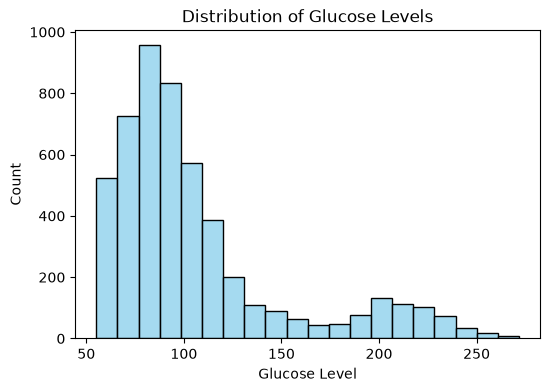

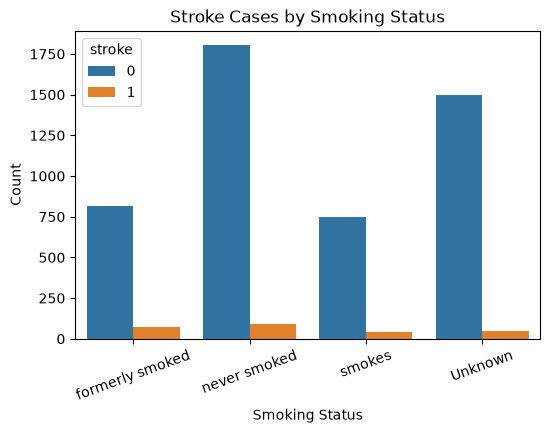

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Graph 1: Histogram of Glucose Levels
plt.figure(figsize=(6, 4))
sns.histplot(df_clean['avg_glucose_level'], bins=20, color='skyblue')
plt.title('Distribution of Glucose Levels')
plt.xlabel('Glucose Level')
plt.ylabel('Count')
plt.show()

# Graph 2: Bar Chart of Smoking Status
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='smoking_status', hue='stroke')
plt.title('Stroke Cases by Smoking Status')
plt.xlabel('Smoking Status')
plt.ylabel('Count')
plt.xticks(rotation=20)
plt.show()

In [6]:
# Turn 'ever_married' (Yes/No) into 1 and 0
df_clean['ever_married'] = df_clean['ever_married'].map({'Yes': 1, 'No': 0})

# One-hot encode remaining text columns
text_columns = ['gender', 'work_type', 'Residence_type', 'smoking_status']
df_encoded = pd.get_dummies(df_clean, columns=text_columns, drop_first=True)

df_encoded.head()

,age,hypertension,heart_disease,ever_married,avg_glucose_level,bmi,stroke,gender_Male,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,1,228.69,36.6,1,True,False,True,False,False,True,True,False,False
1,61.0,0,0,1,202.21,28.1,1,False,False,False,True,False,False,False,True,False
2,80.0,0,1,1,105.92,32.5,1,True,False,True,False,False,False,False,True,False
3,49.0,0,0,1,171.23,34.4,1,False,False,True,False,False,True,False,False,True
4,79.0,1,0,1,174.12,24.0,1,False,False,False,True,False,False,False,True,False


In [7]:
from sklearn.preprocessing import StandardScaler

# Scale continuous numerical columns to have mean = 0, std = 1
scaler = StandardScaler()
cols_to_scale = ['age', 'avg_glucose_level', 'bmi']

df_encoded[cols_to_scale] = scaler.fit_transform(df_encoded[cols_to_scale])

# Verify scaled values
df_encoded[cols_to_scale].head()

,age,avg_glucose_level,bmi
0,1.051242,2.706450,1.004893
1,0.785889,2.121652,-0.099142
2,1.626174,-0.004867,0.472358
3,0.255182,1.437473,0.719142
4,1.581949,1.501297,-0.631677


In [8]:
# Save to a new CSV file
df_encoded.to_csv('cleaned_stroke_data.csv', index=False)

print("Saved successfully!")
print("Final Shape:", df_encoded.shape)
print("Remaining Missing Values:", df_encoded.isnull().sum().sum())

Saved successfully!
Final Shape: (5109, 16)
Remaining Missing Values: 0
